In [5]:
import zipfile
import pandas as pd

feeds = {
    "Chicago": "DataVis_Transit/gtfs/cta.zip",
    "Philadelphia": "DataVis_Transit/gtfs/septa.zip",
    "Boston": "DataVis_Transit/gtfs/mbta.zip"
}

all_stops = {}

for city, path in feeds.items():

    with zipfile.ZipFile(path) as z:

        folder = z.namelist()[0].split("/")[0]

        stops = pd.read_csv(
            z.open(f"{folder}/stops.txt")
        )

        all_stops[city] = stops

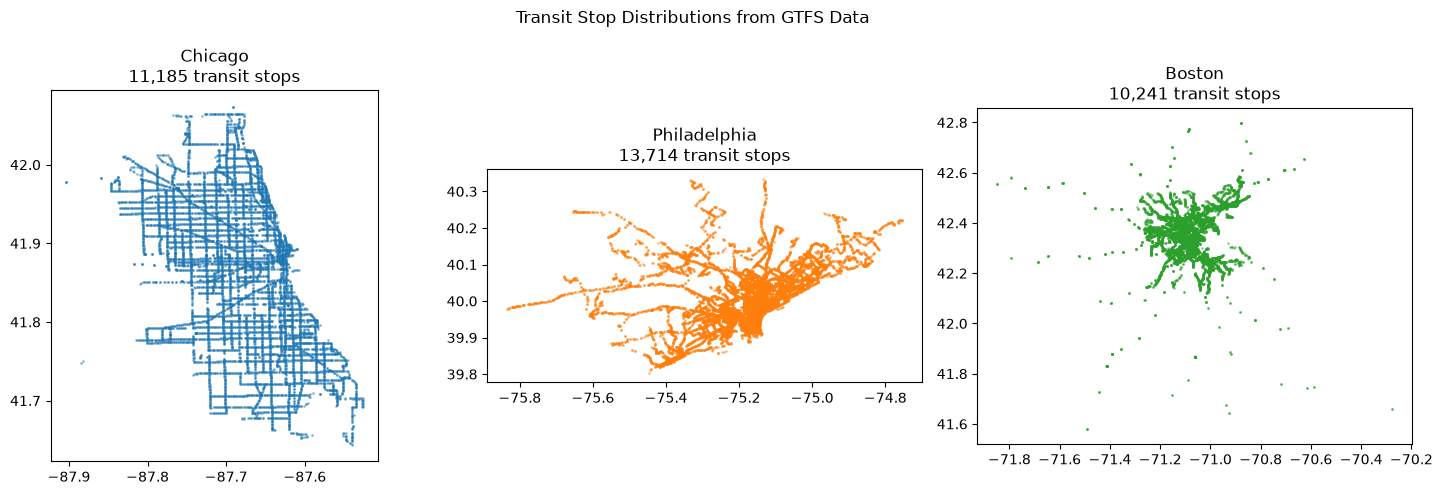

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors = {
    "Chicago": "#1f77b4",
    "Philadelphia": "#ff7f0e",
    "Boston": "#2ca02c"
}

len(stops)

for ax, (city, stops) in zip(axes, all_stops.items()):

    ax.scatter(
    stops["stop_lon"],
    stops["stop_lat"],
    s=1,
    alpha=0.4,
    color=colors[city]
)

    ax.set_title(
    f"{city}\n{len(stops):,} transit stops"
)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    
    ax.set_aspect('equal')

    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle(
    "Transit Stop Distributions from GTFS Data"
)

plt.tight_layout()
plt.show()